# M02: Training and evaluation: results of the remote Kaggle run

This notebook **reads and presents** the saved outputs of the Kaggle run (`results/metrics.json`, `results/predictions.csv`, figures). The training itself ran remotely via `notebooks/kaggle/train_and_evaluate.py`. Nothing below is recomputed or hand-edited.

> Academic research prototype; outputs are not a medical diagnosis.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd()
for cand in (ROOT, ROOT.parent, ROOT.parent.parent):
    if (cand / "src" / "drscreen").is_dir():
        sys.path.insert(0, str(cand / "src")); ROOT = cand; break
# On Kaggle the package is embedded in the kernel script; for notebooks, upload src/drscreen as a Dataset or copy it next to the notebook.
DATA_ROOT = os.environ.get("DR_DATA_ROOT") or ("/kaggle/input/aptos2019-blindness-detection" if Path("/kaggle/input").exists() else str(ROOT / "data" / "aptos2019"))
print("project root:", ROOT, "| data root:", DATA_ROOT)
import json
from IPython.display import display, Image, Markdown
RES = ROOT / 'results'; FIG = ROOT / 'report' / 'figures'
m = json.loads((RES / 'metrics.json').read_text())
print('run:', m['environment'].get('gpu'), '| epochs completed:', m['run']['epochs_completed'], '| stop reason:', m['run']['stop_reason'])

project root: C:\Users\shaik\OneDrive\Desktop\Diabetic Retinopathy CNN | data root: C:\Users\shaik\OneDrive\Desktop\Diabetic Retinopathy CNN\data\aptos2019
run: Tesla T4 | epochs completed: 29 | stop reason: early stopping: no improvement in validation qwk for 8 epochs


In [2]:
from drscreen.metrics import metrics_table_rows
from drscreen.report import md_table
h = m['internal_holdout']; s = h['screening']
print(h['dataset'], '|', h['evaluation_type'], '| n =', h['n_samples'], '| positives =', s['n_positive'], '| prevalence = %.3f' % s['prevalence'], '| threshold = %.3f (chosen on validation)' % s['threshold'])
display(Markdown(md_table(['Metric','Measured result','95% CI','What it means','Why it matters'], metrics_table_rows(h))))

APTOS 2019 internal test split | internal holdout (same source as training) | n = 519 | positives = 205 | prevalence = 0.395 | threshold = 0.628 (chosen on validation)


| Metric | Measured result | 95% CI | What it means | Why it matters |
|---|---|---|---|---|
| Sensitivity (recall) | 0.932 | 0.896 to 0.964 | Of truly referable cases, the share the system flagged. | Missed referable cases (false negatives) are the costly error in screening. |
| Specificity | 0.955 | 0.933 to 0.976 | Of truly non-referable cases, the share correctly passed as non-referable. | Low specificity floods reviewers with false alarms. |
| Precision (PPV) | 0.932 | 0.897 to 0.964 | Of all cases flagged referable, the share that really were. | Depends on prevalence; tells how trustworthy a flag is. |
| Negative predictive value | 0.955 | 0.931 to 0.975 | Of cases passed as non-referable, the share that really were. | How reassuring a 'no referral' result is. |
| ROC-AUC | 0.987 | 0.979 to 0.994 | Probability a random referable case scores higher than a random non-referable case. | Threshold-free separation ability. |
| PR-AUC (average precision) | 0.979 | 0.964 to 0.991 | Area under the precision-recall curve. | More informative than ROC-AUC when referable cases are the minority. |
| Balanced accuracy | 0.944 | 0.920 to 0.963 | Mean of sensitivity and specificity. | Not distorted by class imbalance. |
| F1 score | 0.932 | 0.904 to 0.956 | Harmonic mean of precision and sensitivity. | Single number balancing flags and misses. |
| Quadratic weighted kappa | 0.910 | 0.884 to 0.930 | Agreement between predicted and true grade beyond chance; disagreements are penalised by the squared grade distance. | Predicting grade 0 for a grade 4 eye is punished far more than grade 2 vs 3. |
| Macro F1 (5 grades) | 0.713 | 0.656 to 0.758 | Unweighted mean of per-grade F1. | Rewards doing well on rare severe grades. |
| Balanced accuracy (5 grades) | 0.688 | 0.633 to 0.740 | Mean of per-grade recall. | Each grade counts equally. |
| Accuracy (5 grades, secondary) | 0.830 | 0.796 to 0.859 | Share of exact grade matches. | Misleading alone under class imbalance. |
| Expected calibration error | 0.042 | n/a | Average gap between confidence and observed accuracy over equal-width bins. | Shows whether probabilities can be read as frequencies. |
| Brier score | 0.041 | 0.031 to 0.054 | Mean squared error of the referable probability (lower is better). | Proper scoring rule: rewards honest probabilities. |

TP=191  FP=14  TN=300  FN=14  (FN = missed referable cases; FP = false alarms)

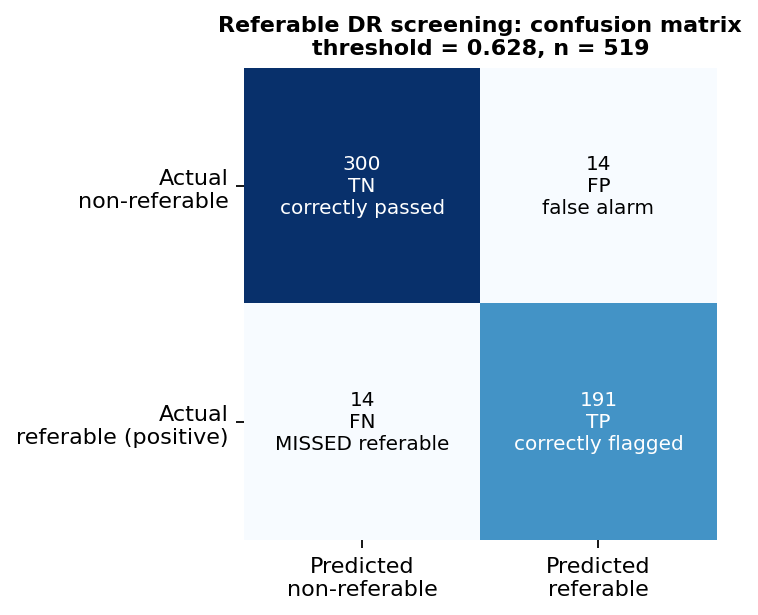

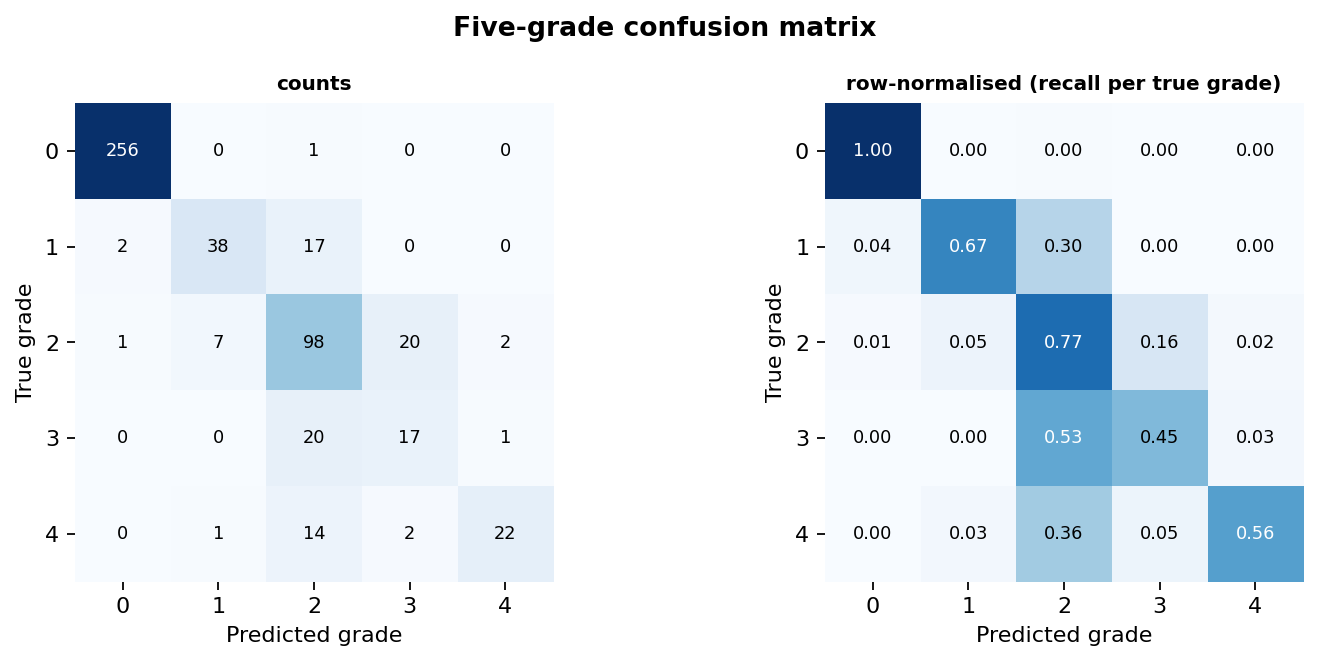

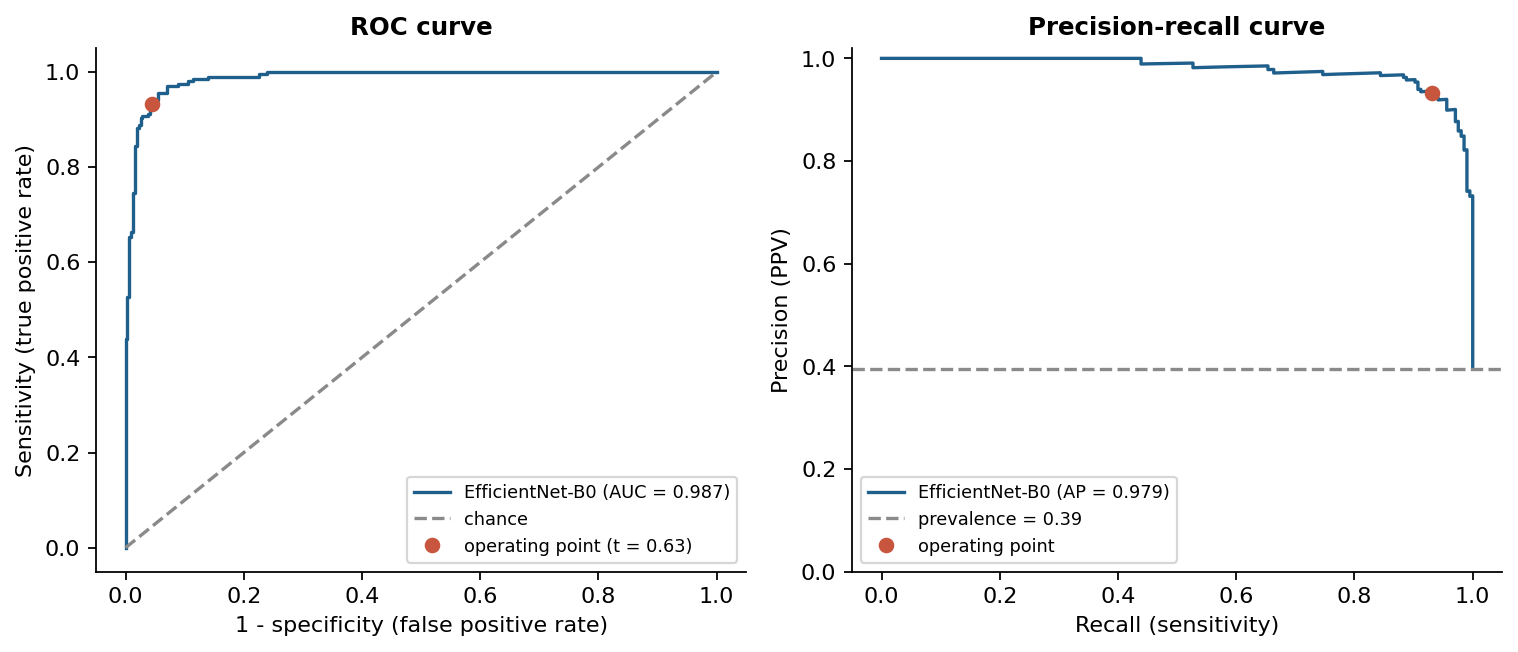

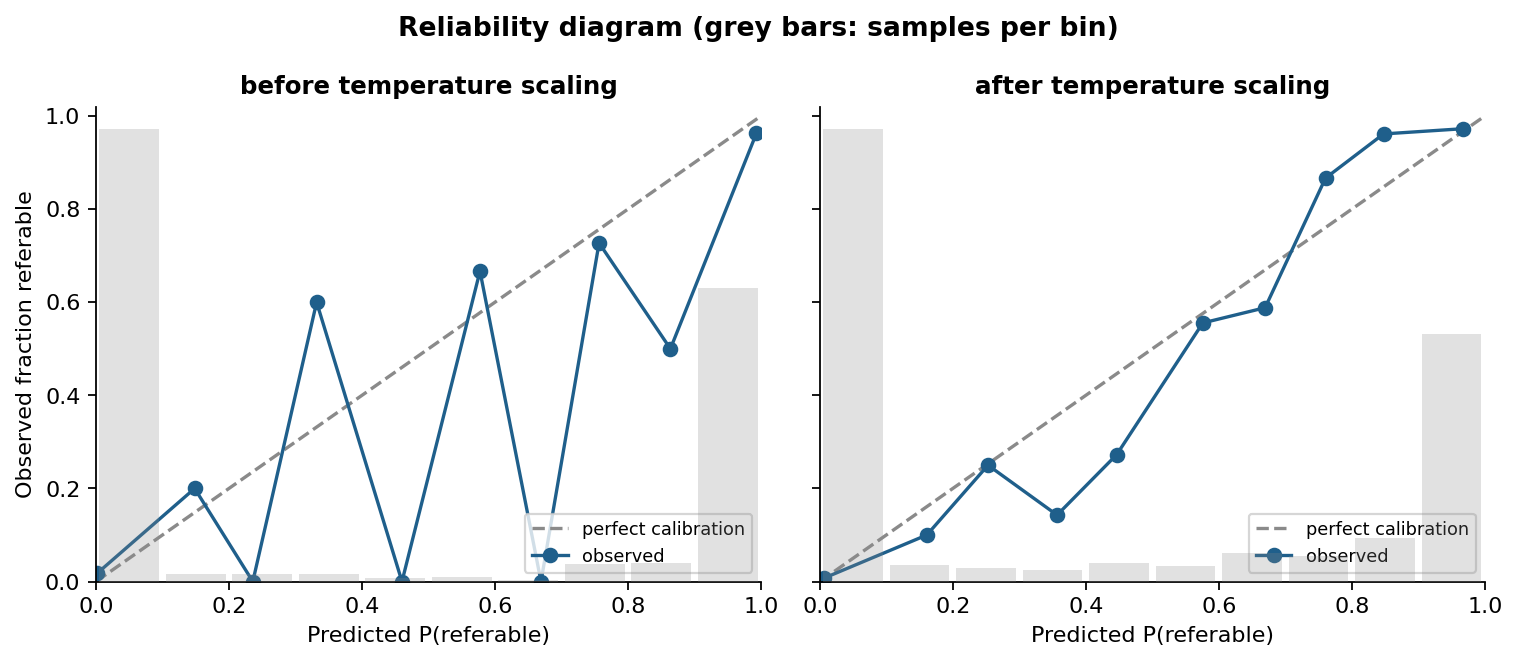

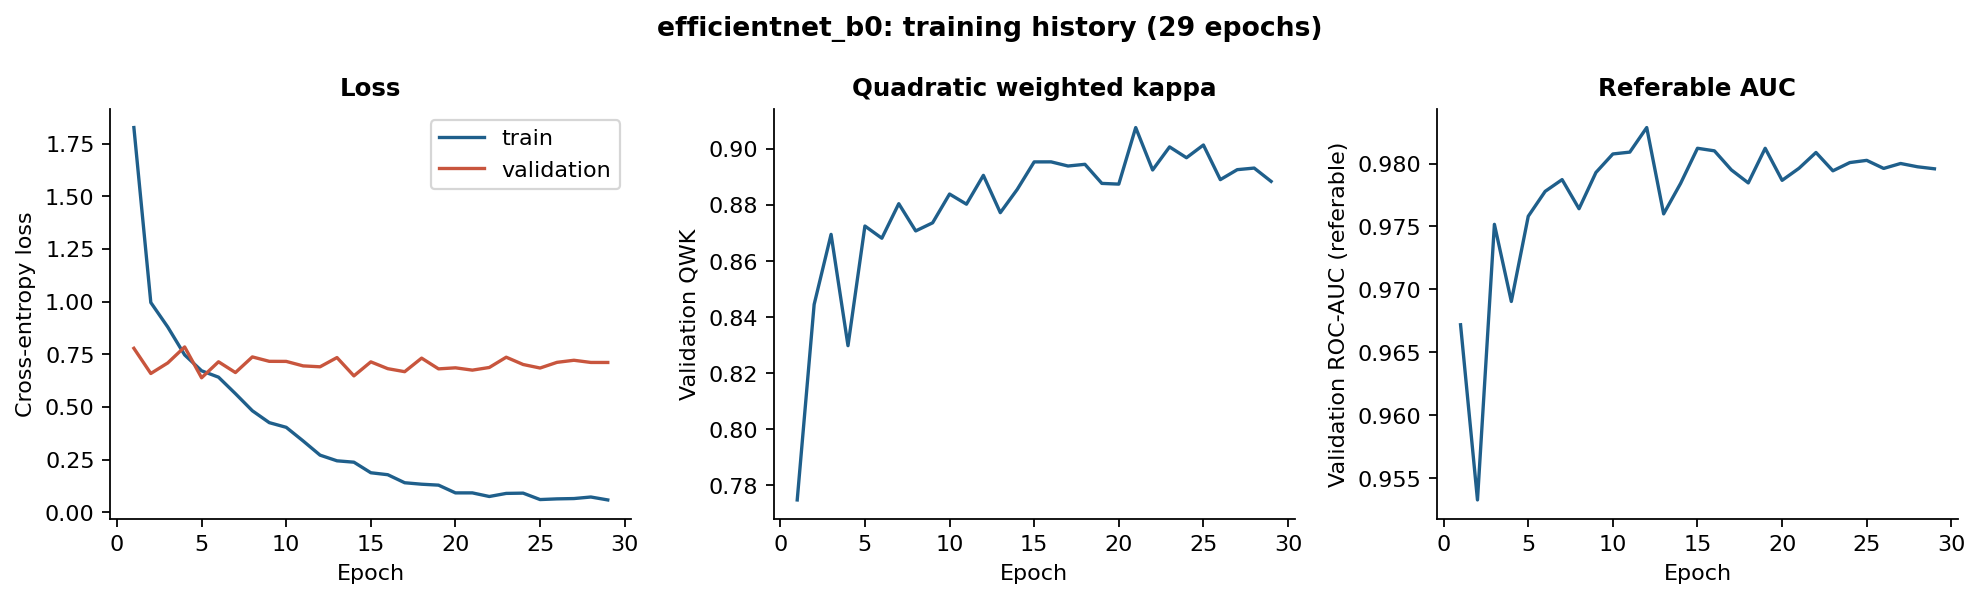

In [3]:
display(Markdown(f"TP={s['tp']}  FP={s['fp']}  TN={s['tn']}  FN={s['fn']}  (FN = missed referable cases; FP = false alarms)"))
for f in ['confusion_referable.png','confusion_5grade.png','roc_pr.png','reliability.png','learning_curves.png']:
    if (FIG / f).exists(): display(Image(str(FIG / f)))

[figure omitted from the public repository: it shows dataset photographs (APTOS 2019 terms); regenerated locally by the notebook]


[figure omitted from the public repository: it shows dataset photographs (APTOS 2019 terms); regenerated locally by the notebook]


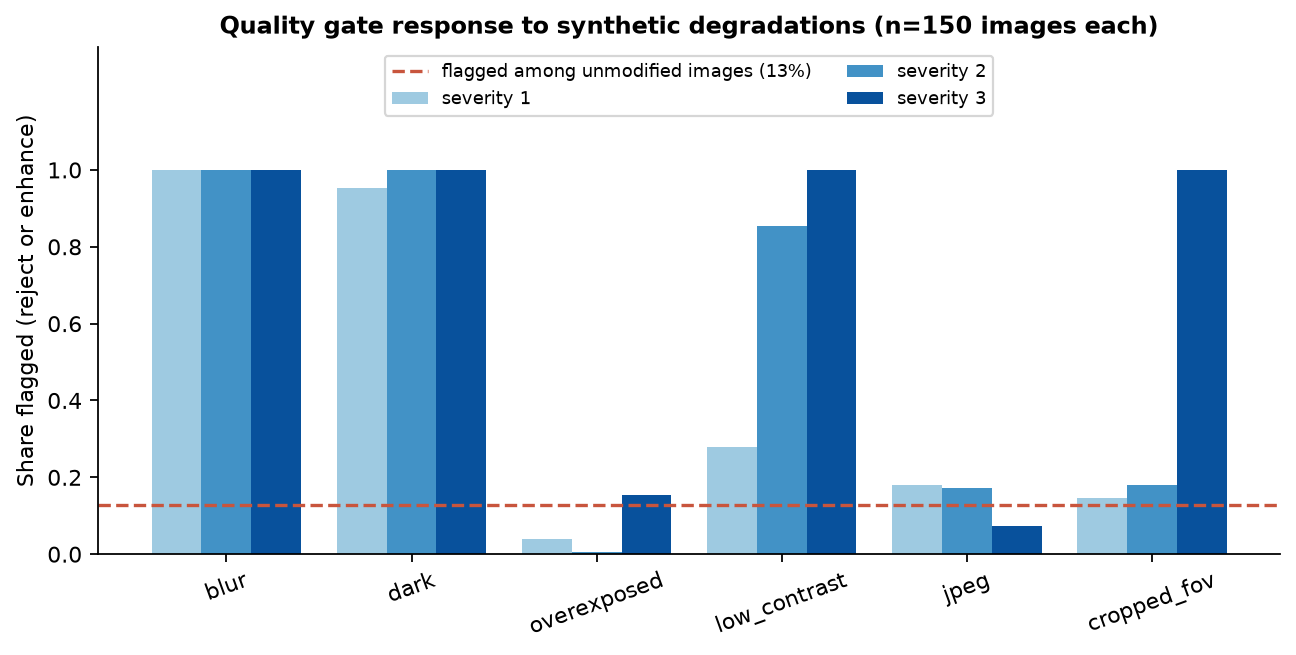

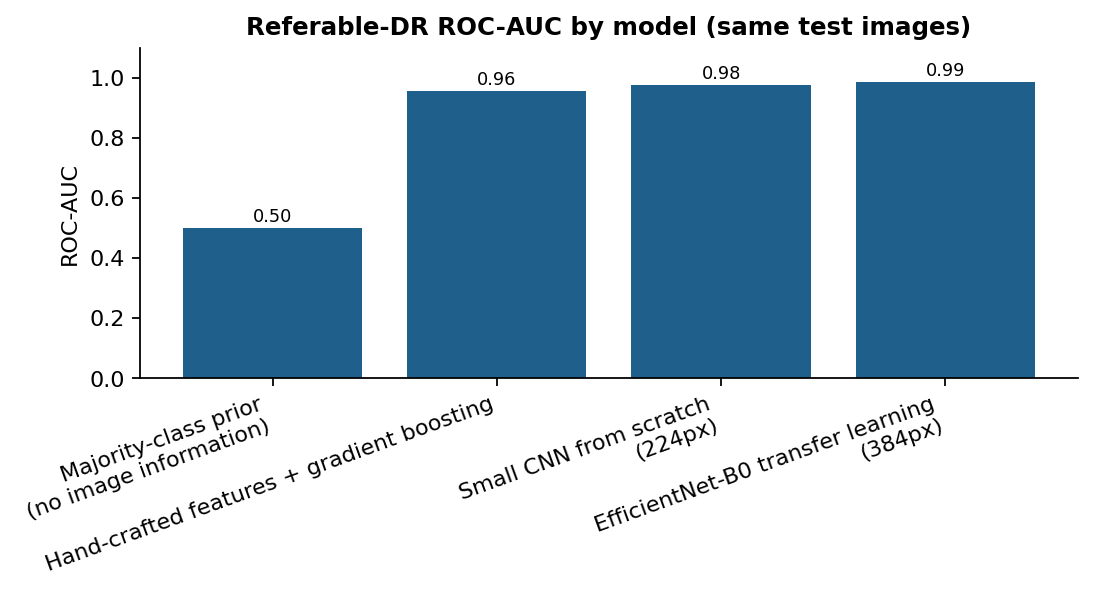

Ablation:


| Configuration | N | Sens. | Spec. | AUC | QWK |
|---|---|---|---|---|---|
| Majority-class prior (no image information) | 519 | 1.0 | 0.0 | 0.5 | 0.0 |
| Hand-crafted features + gradient boosting | 519 | 0.9414634146341463 | 0.8343949044585988 | 0.9575889389467143 | 0.7550941114065525 |
| Small CNN from scratch (224px) | 519 | 0.9609756097560975 | 0.9044585987261147 | 0.9780487804878047 | 0.8500276822658663 |
| EfficientNet-B0 transfer learning (384px) | 519 | 0.9317073170731708 | 0.9554140127388535 | 0.9870902594376262 | 0.9100260040450737 |
| EfficientNet-B0 + quality gate (rejected counted as referred) | 519 | 0.9170731707317074 | 0.9299363057324841 | None | None |
| EfficientNet-B0 + quality gate + human-review band (both counted as referred) | 519 | 0.9414634146341463 | 0.910828025477707 | None | None |

In [4]:
for f in ['gradcam_examples.png','error_examples.png','quality_degradation.png','ablation_auc.png']:
    if (FIG / f).exists(): display(Image(str(FIG / f)))
print('Ablation:'); display(Markdown(md_table(['Configuration','N','Sens.','Spec.','AUC','QWK'], [[r['name'], r['n'], r.get('sensitivity'), r.get('specificity'), r.get('roc_auc'), r.get('qwk')] for r in m.get('ablation', [])])))

In [5]:
RUN_TRAINING = False  # training is meant to run on Kaggle's GPU; set True only on a GPU machine with the data present
if RUN_TRAINING:
    from drscreen.pipeline import Run, RunConfig
    Run(RunConfig(data_root=DATA_ROOT, work_dir=str(ROOT / 'outputs'))).run_all()